In [ ]:
from pelmesha.kneading import peakpicker, smoothing, peakpicker_legacy
import numpy as np
from pelmesha.kneading import resample_mz_scale, add_zero_points_to_peaks
from pelmesha.utensils import mspeaks_KD
from pelmesha.filling import DataSource
path_list = [r'D:\Testing\Our_data\Rapiflex\roi8_e040\roi8_e040.imzML',
            r"C:\Job_and_Literature\Esi_test\3_t.cdf",
            r"C:\Job_and_Literature\Esi_test\3_t.cdf",
            r'D:\Testing\Our_data\Orbitrap\1\test1.imzML']
# path_list = [r'D:\Testing\Our_data\Orbitrap\1\test1.imzML']
roi_list = ["R00",'1',"2","R00"]
# roi_list = ['R00']
roi_iter = iter(roi_list)
args = {"heightfilter": None,
        'rel_heightfilter': None,
        'SNR_threshold': 3.5,
        'noise_mz_width': 10,
        'noise_est_iter': 3,
        'fwhm_merge_factor': 0.84,
        'return_areas': True,
        'fwhm_filter': None,
        'resampled_discontiniuous': True
        }
for path in path_list:
    ds = DataSource(path)
    roi = next(roi_iter)
    # print(ds.roi_metadata)
    print(f"{ds.sample_name} {roi}")
    print(ds.roi_metadata.index)

    index = ds.roi_metadata.loc[roi,'idxroi']
    mz_discret_coeffs = ds.roi_metadata.loc[roi,'discret_coeffs']
    # print(ds.get_coords(index[0,0]))
    # print(index[0,0])
    # print(discret_coeffs)
    mz, intens = ds.get_spectrum(index[0,0])
    mz, intens = add_zero_points_to_peaks(mz, intens, mz_discret_coeffs)
    mz_new = resample_mz_scale(*ds.roi_metadata.loc[roi,'mz_range'], 0.0025)
    intens_new = np.interp(mz_new, mz, intens)
    mz = mz_new
    intens = intens_new
    # intens = smoothing(intens, smooth_algo= 'GA')
    from pelmesha.utensils import mspeaks_KD
    s_1 = peakpicker_legacy(mz, intens, 1, SNR_threshold=3.5, oversegmentationfilter=0.15)
    s_2 = peakpicker(mz, intens,1, **args)

    
    pmz,left,right, pky = mspeaks_KD(mz,intens)
    pext_array = np.vstack([left,right]).T
    indext_array = np.searchsorted(mz,pext_array, side='left')

    %timeit peakpicker(mz, intens, 1,**args)

    %timeit peakpicker_legacy(mz, intens, 1, SNR_threshold=3.5, oversegmentationfilter=0.15)



c:\Job_and_Literature\Programming\Python\projects\pelmesha\.venv\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000046 found with incorrect name "pixel size". Updating name to "pixel size (x)".
  warn(


roi8_e040 R00
Index(['R00'], dtype='str')
405 ms ± 11.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
83.2 ms ± 1.83 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
Esi_test_3_t 1
Index(['0', '1', '2', '3'], dtype='str')
130 ms ± 4.3 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
83.5 ms ± 1.44 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
Esi_test_3_t 2
Index(['0', '1', '2', '3'], dtype='str')
12.1 ms ± 123 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
179 ms ± 13 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


c:\Job_and_Literature\Programming\Python\projects\pelmesha\.venv\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000563 found with incorrect name "Thermo RAW file". Updating name to "Thermo RAW format".
  warn(
c:\Job_and_Literature\Programming\Python\projects\pelmesha\.venv\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000590 found with incorrect name "contact organization". Updating name to "contact affiliation".
  warn(
c:\Job_and_Literature\Programming\Python\projects\pelmesha\.venv\Lib\site-packages\pyimzml\ontology\ontology.py:84: UserWarning: Accession MS:1000128 ("profile spectrum") found with mismatched name "positive scan". This is a known bug with some imzML conversion software - using accession MS:1000130 ("positive scan") instead.
  warn(
c:\Job_and_Literature\Programming\Python\projects\pelmesha\.venv\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000042 found with incorrect name

1_test1 R00
Index(['R00'], dtype='str')
6.74 ms ± 560 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
65.7 ms ± 754 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
from pelmesha.filling import DataSource
from pelmesha.kneading import smoothing
import numpy as np
path = r'D:\Testing\Our_data\Rapiflex\roi8_e040\roi8_e040.imzML'
path = r"C:\Job_and_Literature\Esi_test\3_t.cdf"

# path = r'D:\Testing\Our_data\Orbitrap\1\test1.imzML'
ds = DataSource(path)

# print(ds.roi_metadata)
discret_coeffs = ds.roi_metadata.loc['R00','discret_coeffs']
index = ds.roi_metadata.loc['R00','idxroi']
# print(ds.get_coords(index[0,0]))
# print(index[0,0])

mz, intens = ds.get_spectrum(index[0,0])
# intens = smoothing(intens, smooth_algo= 'GA')
from pelmesha.utensils import mspeaks_KD


pmz,left,right, pky = mspeaks_KD(mz,intens)
pext_array = np.vstack([left,right]).T
indext_array = np.searchsorted(mz,pext_array, side='left')

KeyError: 'R00'

In [ ]:
from numba import njit
import numpy as np

@njit
def noise_finder(intens: np.ndarray,
                 mz: np.ndarray,
                 pint_array: np.ndarray, 
                 pext_array: np.ndarray,
                 discret_coefs: np.ndarray,
                 SNR_threshold: float = 3.5, 
                 mz_window: float = 5,
                 iter: int = 3):
    """
    pext - (N,2) size
    mz_window + discret_coefs = local dots_window
    Возможно флаг добавить, чтобы переключало либо в dots, либо mz
    """
    discret_coefs = discret_coefs[::-1]  # переворачиваем коэффициенты

    n_peaks = len(pext_array)
    noise_bool = np.ones(len(intens),dtype = np.bool_)
    dots_half = np.zeros(n_peaks,dtype = np.int32)
    noise_std = np.zeros(n_peaks,dtype = np.float64)
    noise_mean = np.zeros(n_peaks,dtype = np.float64)
    psl_left = np.zeros(n_peaks,dtype = np.int32)
    psl_right = np.zeros(n_peaks,dtype = np.int32)
    for n, (pext_left, pext_right) in enumerate(pext_array):
        mzd_val = 0.0
        loc_mz = mz[pext_left]
        for c in discret_coefs:
            mzd_val = mzd_val * loc_mz + c
        n_half = mz_window//(2*mzd_val)
        dots_half[n] = n_half 

        count = 0        
        for i in range(pext_left, -1,-1):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == 0:
                    sl_left = i
                    break

        count = 0
        for i in range(pext_right, len(intens)):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == len(intens)-1:
                    sl_right = i
                    break

        loc_slice = slice(sl_left, sl_right+1)
        local_bool = noise_bool[loc_slice]
        local_int = intens[loc_slice][local_bool]
        noise_std[n] = np.std(local_int)
        noise_mean[n] = np.mean(local_int)
        psl_left[n] = sl_left
        psl_right[n] = sl_right
    k = (pint_array - noise_mean)/noise_std >= SNR_threshold

    for _ in range(iter-1):
        for b, (pext_left, pext_right) in zip(k, pext_array):
            noise_bool[pext_left:pext_right+1] = ~b 
        for n, (pext_left, pext_right) in enumerate(pext_array):
            n_half = dots_half[n] 

            count = 0        
            for i in range(pext_left, -1,-1):
                if noise_bool[i]:
                    count += 1
                    if count == n_half or i == 0:
                        sl_left = i
                        break

            count = 0
            for i in range(pext_right, len(intens)):
                if noise_bool[i]:
                    count += 1
                    if count == n_half or i == len(intens)-1:
                        sl_right = i
                        break
            if psl_left[n] != sl_left and psl_right[n] != sl_right:
                loc_slice = slice(sl_left, sl_right+1)
                local_bool = noise_bool[loc_slice]
                local_int = intens[loc_slice][local_bool]
                noise_std[n] = np.std(local_int)
                noise_mean[n] = np.mean(local_int)
                psl_left[n] = sl_left
                psl_right[n] = sl_right
        SNR = (pint_array - noise_mean)/noise_std
        k = SNR >= SNR_threshold
    return k, SNR[k], noise_std[k], noise_mean[k]
@njit
def fast_noise_finder(intens: np.ndarray,
                 pint_array: np.ndarray, 
                 pext_array: np.ndarray,
                 SNR_threshold: float = 3.5, 
                 iter: int = 3):
    xsize = intens.size
    noise_bool = np.ones(xsize, dtype = np.bool_) # Zero iteration

    for it in range(iter):
        noise_func_full = np.std(intens[noise_bool])
        noise_mean_full = np.mean(intens[noise_bool])
        for idx in np.where(((pint_array-noise_mean_full)/noise_func_full>=SNR_threshold))[0]: # Essentially a plain z-score.
            sl = slice(pext_array[idx,:][0], pext_array[idx,:][1]+1)
            noise_bool[sl] = False
    
    noise_std = np.std(intens[noise_bool])
    noise_mean= np.mean(intens[noise_bool])
    SNR = (pint_array - noise_mean)/noise_std
    k = SNR>=SNR_threshold
    size = np.sum(k)
    noise_std = np.empty(size, dtype=np.float64).fill(noise_std)
    noise_mean = np.empty(size, dtype=np.float64).fill(noise_mean)
    return k, SNR[k], noise_std, noise_mean

In [ ]:
from numba import njit
import numpy as np

@njit
def noise_finder_v2(intens: np.ndarray,
                 mz: np.ndarray,
                 pint_array: np.ndarray, 
                 pext_array: np.ndarray,
                 discret_coefs: np.ndarray,
                 SNR_threshold: float = 3.5, 
                 mz_window: float = 5,
                 iter: int = 3):
    """
    pext - (N,2) size
    mz_window + discret_coefs = local dots_window
    Возможно флаг добавить, чтобы переключало либо в dots, либо mz
    """
    discret_coefs = discret_coefs[::-1]  # переворачиваем коэффициенты

    n_peaks = len(pext_array)
    xsize = intens.size
    noise_bool = np.ones(xsize,dtype = np.bool_)
    dots_half = np.zeros(n_peaks,dtype = np.int32)
    noise_std = np.zeros(n_peaks,dtype = np.float64)
    noise_mean = np.zeros(n_peaks,dtype = np.float64)
    psl_left = np.zeros(n_peaks,dtype = np.int32)
    psl_right = np.zeros(n_peaks,dtype = np.int32)
    for n in range(n_peaks):
        pext_left = pext_array[n, 0]
        pext_right = pext_array[n, 1]
        mzd_val = 0.0
        loc_mz = mz[pext_left]
        for c in discret_coefs:
            mzd_val = mzd_val * loc_mz + c
        n_half = mz_window//(2*mzd_val)
        dots_half[n] = n_half 

        count = 0        
        for i in range(pext_left, -1,-1):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == 0:
                    sl_left = i
                    break

        count = 0
        for i in range(pext_right, xsize):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == xsize-1:
                    sl_right = i
                    break

        sum_ = 0.0
        sum_sq = 0.0
        count_local = 0

        for i in range(sl_left, sl_right + 1):
            if noise_bool[i]:
                val = intens[i]
                sum_ += val
                sum_sq += val * val
                count_local += 1

        if count_local > 0:
            mean = sum_ / count_local
            var = (sum_sq / count_local) - mean * mean
            std = np.sqrt(var) if var > 0 else 0.0
        else:
            mean, std = 0.0, 0.0
        noise_std[n] = std
        noise_mean[n] = mean

        psl_left[n] = sl_left
        psl_right[n] = sl_right
    k = (pint_array - noise_mean)/noise_std >= SNR_threshold

    for _ in range(iter-1):
        for n in range(n_peaks):
            b = k[n]
            pext_left = pext_array[n, 0]
            pext_right = pext_array[n, 1]
            noise_bool[pext_left:pext_right+1] = ~b
        for n in range(n_peaks):
            pext_left = pext_array[n, 0]
            pext_right = pext_array[n, 1]
            n_half = dots_half[n] 

            count = 0        
            for i in range(pext_left, -1,-1):
                if noise_bool[i]:
                    count += 1
                    if count == n_half or i == 0:
                        sl_left = i
                        break

            count = 0
            for i in range(pext_right, xsize):
                if noise_bool[i]:
                    count += 1
                    if count == n_half or i == xsize-1:
                        sl_right = i
                        break
            if psl_left[n] != sl_left and psl_right[n] != sl_right:
                sum_ = 0.0
                sum_sq = 0.0
                count_local = 0

                for i in range(sl_left, sl_right + 1):
                    if noise_bool[i]:
                        val = intens[i]
                        sum_ += val
                        sum_sq += val * val
                        count_local += 1

                if count_local > 0:
                    mean = sum_ / count_local
                    var = (sum_sq / count_local) - mean * mean
                    std = np.sqrt(var) if var > 0 else 0.0
                else:
                    mean, std = 0.0, 0.0
                noise_std[n] = std
                noise_mean[n] = mean


                psl_left[n] = sl_left
                psl_right[n] = sl_right
        SNR = (pint_array - noise_mean)/noise_std
        k = SNR >= SNR_threshold
    return k, SNR[k], noise_std[k], noise_mean[k]


In [ ]:

@njit
def prepend(arr, number):
    result = np.empty(len(arr) + 1, dtype=arr.dtype)
    result[0] = number
    result[1:] = arr
    
    return result
@njit
def append(arr, number):
    result = np.empty(len(arr) + 1, dtype=arr.dtype)
    result[:-1] = arr
    result[-1] = number
    return result

@njit
def fwhm_interp(pmz_array: np.ndarray[float], 
                pint_array: np.ndarray[float], 
                left_min: np.ndarray[int], 
                right_min: np.ndarray[int]):
    n_peaks = pmz_array.size

    fwhm_left = np.empty(n_peaks, dtype= np.float64)
    fwhm_right = np.empty(n_peaks, dtype= np.float64)
    for n in range(n_peaks):
        lm =  left_min[n]
        rm =  right_min[n]
        vm = pint_array[n]
        pp = pmz_array[n]
        half_max = vm / 2.0
        fwhm_left[n] = np.interp(
        half_max, intens[lm : pp + 1], mz[lm : pp + 1]
        )
        fwhm_right[n] = np.interp(
            half_max, intens[pp : rm + 1][::-1], mz[pp : rm + 1][::-1]
        )
    return fwhm_left, fwhm_right

@njit
def noise_finder_v3(mz: np.ndarray,
                    intens: np.ndarray,
                    heightfilter: float | None = None,
                    rel_heightfilter: float | None = None,
                    fwhmfilter: np.ndarray[float] | None = None,
                    SNR_threshold: float | None = 3.5,
                    noise_mz_width: float = 5,
                    discret_coeffs: np.ndarray | None = None,
                    fwhm_merge_factor: float | None = None,
                    peaklocation: float = 1,
                    return_areas: bool = False,
                    iter: int = 3):
    """
    pext - (N,2) size
    mz_window + discret_coefs = local dots_window
    Возможно флаг добавить, чтобы переключало либо в dots, либо mz
    """
    xsize = intens.size
    valley_dots = np.where(np.diff(intens) !=0)[0] 
    valley_dots = append(valley_dots,xsize-1)    
    loc_min = np.diff(intens[valley_dots])
    loc_min = (np.array([True,*(loc_min < 0)])) & np.array(([*(loc_min > 0),True]))
    left_min = prepend(valley_dots[:-1],-1)[loc_min][:-1] + 1
    right_min = valley_dots[loc_min][1:]

    # Compute max for every peak
    n_peaks = left_min.size
    pint_array = np.empty(n_peaks,dtype=np.float64)
    pmz_array = np.empty(n_peaks,dtype=np.int64)
    for idx in range(n_peaks):
        lm = left_min[idx]
        rm = right_min[idx]
        pint_array[idx] = np.max(intens[lm:rm])
        pmz_array[idx] = lm + np.argmax(intens[lm:rm])

    # Remove peaks below the height, relative height
    if heightfilter is not None and rel_heightfilter is not None:
        k = (pint_array >= heightfilter) & (pint_array/max(intens) >= rel_heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]
    elif heightfilter is not None:
        k = (pint_array >= heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]
    elif rel_heightfilter is not None:
        k = (pint_array/max(intens) >= rel_heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]

    n_peaks = pint_array.size
    noise_bool = np.ones(xsize,dtype = np.bool_)
    dots_half = np.zeros(n_peaks,dtype = np.int64)
    noise_std = np.zeros(n_peaks,dtype = np.float64)
    noise_mean = np.zeros(n_peaks,dtype = np.float64)
    psl_left = np.zeros(n_peaks,dtype = np.int64)
    psl_right = np.zeros(n_peaks,dtype = np.int64)

    quantile_threshold = np.quantile(pint_array,0.50) #Считаем, что больше половины интенсивностей ниже этого значения - чистый шум,
                                                      #поэтому затравочный фильтр => какие точки - сигнал, а какие шум определяем по этому значению
    filtered = pint_array <= quantile_threshold
    for n in range(n_peaks):
        pext_left = left_min[n]
        pext_right = right_min[n]

        noise_bool[pext_left:pext_right+1] = filtered[n] 

    for n in range(n_peaks):
        pext_left = left_min[n]
        pext_right = right_min[n]
        mzd_val = 0.0
        loc_mz = mz[pmz_array[n]]
        if discret_coeffs is not None:
            for c in discret_coeffs:
                mzd_val = mzd_val * loc_mz + c
        else:
            mzd_val = 1 # noise_mz_width - считается по точкам теперь, а не по абсолутному значению m/z
        n_half = noise_mz_width//(2*mzd_val)
        if n_half <=1:
            print(mzd_val)
        dots_half[n] = n_half 

        count = 0        
        for i in range(pext_left, -1,-1):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == 0:
                    sl_left = i
                    break

        count = 0
        for i in range(pext_right, xsize):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == xsize-1:
                    sl_right = i
                    break
                
        sum_ = 0.0
        sum_sq = 0.0
        count_local = 0
        local_noise_bool = noise_bool[slice(sl_left, sl_right + 1)]
        noise_size = local_noise_bool.sum()
        unnoise_size = (~local_noise_bool).sum()
        if noise_size >2 or unnoise_size == 0:
            for i in range(sl_left, pext_left +1): 
                if noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
            for i in range(pext_right, sl_right + 1):
                if noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
        else:
            for i in range(sl_left, pext_left +1): 
                if ~noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
            for i in range(pext_right, sl_right + 1):
                if ~noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1

        mean = sum_ / count_local
        # var = (sum_sq / count_local) - mean * mean # ddof = 0
        var = ((sum_sq - sum_ * mean) / (count_local - 1)) # ddof = 1
        std = np.sqrt(var) if var > 0 else 0.0
        
        noise_std[n] = std
        noise_mean[n] = mean

        psl_left[n] = sl_left
        psl_right[n] = sl_right
    SNR = (pint_array - noise_mean)/noise_std
    k =  SNR >= SNR_threshold
    if iter > 1:
        for _ in range(iter-1):
            for n in range(n_peaks):
                b = k[n]
                pext_left = left_min[n]
                pext_right = right_min[n]
                noise_bool[pext_left:pext_right+1] = ~b

            for n in range(n_peaks):
                pext_left = left_min[n]
                pext_right = right_min[n]
                n_half = dots_half[n] 

                count = 0        
                for i in range(pext_left, -1,-1):
                    if noise_bool[i]:
                        count += 1
                        if count == n_half or i == 0:
                            sl_left = i
                            break

                count = 0
                for i in range(pext_right, xsize):
                    if noise_bool[i]:
                        count += 1
                        if count == n_half or i == xsize-1:
                            sl_right = i
                            break
                if psl_left[n] != sl_left and psl_right[n] != sl_right:
                    sum_ = 0.0
                    sum_sq = 0.0
                    count_local = 0
                    if noise_bool[slice(sl_left, sl_right + 1)].sum() >2:
                        for i in range(sl_left, pext_left +1): 
                            if noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                        for i in range(pext_right, sl_right + 1):
                            if noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                    else:
                        for i in range(sl_left, pext_left +1): 
                            if ~noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                        for i in range(pext_right, sl_right + 1):
                            if ~noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                            
                    mean = sum_ / count_local
                    # var = (sum_sq / count_local) - mean * mean # ddof = 0
                    var = ((sum_sq - sum_ * mean) / (count_local - 1)) # ddof = 1
                    std = np.sqrt(var) if var > 0 else 0.0
                    noise_std[n] = std
                    noise_mean[n] = mean


                    psl_left[n] = sl_left
                    psl_right[n] = sl_right
            SNR = (pint_array - noise_mean)/noise_std
            k = SNR >= SNR_threshold
    pmz_array = pmz_array[k] 
    pint_array = pint_array[k] 
    left_min = left_min[k] 
    right_min = right_min[k] 
    noise_std = noise_std[k]
    noise_mean = noise_mean[k]

    fwhm_left, fwhm_right = fwhm_interp(pmz_array,pint_array, left_min, right_min)
   
    if fwhmfilter is not None:
        fwhm = (fwhm_right - fwhm_left)
        if fwhmfilter.size == 2:
            k = (fwhm >= fwhmfilter[0]) & (fwhm <= fwhmfilter[1])
        elif fwhmfilter.size == 1:
            k = (fwhm >= fwhmfilter)
        else:
            raise ValueError("fwhmfilter must be a scalar or a tuple of two scalars")
        pmz_array = pmz_array[k]
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        fwhm_left = fwhm_left[k]
        fwhm_right = fwhm_right[k]
        noise_std = noise_std[k]
        noise_mean = noise_mean[k]
        
    if fwhm_merge_factor is not None:
        n_peaks = pmz_array.size
        eps = np.sqrt(np.finfo(np.float64).eps)
        # Индексы переразбитых пиков
        j_prealloc = np.empty(n_peaks, dtype=np.int64) # Выносим за цикл while, так как считаем, что почти не затронет памяти, но сэкономит время на создание нового массива в памяти в цикле while
        while True:
            fwhm_res = (fwhm_right - fwhm_left)*fwhm_merge_factor
            peak_thld = pint_array*peaklocation - eps
            pkmz = np.empty(n_peaks, dtype=np.float64)
            
            for n in range(n_peaks):
                lm = left_min[n]
                rm = right_min[n]
                th = peak_thld[n]

                sum_int = 0.0
                sum_mz_int = 0.0
                any_ = False
                for i in range(lm, rm):
                    intens_value = intens[i]
                    if intens_value > th:
                        sum_int += intens_value
                        sum_mz_int += mz[i]*intens_value
                        any_ = True
                pkmz[n] = sum_mz_int / sum_int if any_ else np.nan
            # dpkmz = [inf, diff, inf]
            dpkmz = np.empty(n_peaks + 1, dtype=np.float64)
            for n in range(1, n_peaks):
                dpkmz[n] = pkmz[n] - pkmz[n - 1]
            dpkmz[0] = np.inf
            dpkmz[-1] = np.inf


            count = 0
            for n in range(1, n_peaks):
                prev_n = n - 1
                d = dpkmz[n]
                if d <= fwhm_res[prev_n] and d <= dpkmz[prev_n] and d < dpkmz[n + 1]:
                    j_prealloc[count] = prev_n
                    count += 1
            j = j_prealloc[:count]
            j_size = j.size
            if j_size == 0:
                break

            for unres_peak_idx in range(j_size):
                idx = j[unres_peak_idx]
                idx_next = idx + 1
                if pint_array[idx_next] > pint_array[idx]:
                    pint_array[idx] = pint_array[idx_next]
                    pmz_array[idx] = pmz_array[idx_next]
                    noise_mean[idx] = noise_mean[idx_next]
                    noise_std[idx] = noise_std[idx_next]
            # Удаление
            j_right = j + 1
            left_min = np.delete(left_min, j_right)
            right_min = np.delete(right_min, j)
            pint_array = np.delete(pint_array, j_right)
            noise_std = np.delete(noise_std, j_right)
            noise_mean = np.delete(noise_mean, j_right)
            pmz_array = np.delete(pmz_array, j_right)

            # Обновляем FWHM-массивы (нужно для адаптивного режима)
            fwhm_left = np.delete(fwhm_left, j_right)
            fwhm_right = np.delete(fwhm_right, j)
            n_peaks = left_min.size


    left_bool = (pmz_array - left_min) > 2
    right_bool = (right_min - pmz_array) > 2
    if left_bool.any():
        left_min[left_bool] += 1
    if right_bool.any():
        right_min[right_bool] -= 1
    

    # compute peaks area
    n_peaks = left_min.size
    areas = np.empty(n_peaks, dtype=np.float64)
    if return_areas:
        for idx in range(n_peaks):
            start = left_min[idx]
            end = right_min[idx] + 1
            intens_slice = intens[start:end]
            mz_slice = mz[start:end]
            min_intens = np.min(intens_slice)
            if min_intens < 0:
                offset = -min_intens
            else:
                offset = 0
            area = 0.0
            for i in range(intens_slice.size-1):
                y1 = intens_slice[i] + offset 
                y2 = intens_slice[i+1] + offset
                x1, x2 = mz_slice[i], mz_slice[i+1]
                area += (y1 + y2) * (x2 - x1) / 2
            areas[idx] = area
    fwhm = fwhm_right-fwhm_left
    SNR = (pint_array - noise_mean)/noise_std
    return mz[pmz_array], pint_array, areas, SNR, mz[left_min], mz[right_min], fwhm, noise_std, noise_mean

In [ ]:
@njit
def prepend(arr, number):
    result = np.empty(len(arr) + 1, dtype=arr.dtype)
    result[0] = number
    result[1:] = arr
    
    return result
@njit
def append(arr, number):
    result = np.empty(len(arr) + 1, dtype=arr.dtype)
    result[:-1] = arr
    result[-1] = number
    return result
@njit
def noise_finder_v4(intens: np.ndarray,
                 mz: np.ndarray,
                 discret_coefs: np.ndarray,
                 heightfilter: float = None,
                 rel_heightfilter: float = None,
                 SNR_threshold: float = 3.5, 
                 mz_window: float = 5,
                 fwhm_res_coeff: float = None,
                 peaklocation: float = 1,
                 iter: int = 3):
    """
    pext - (N,2) size
    mz_window + discret_coefs = local dots_window
    Возможно флаг добавить, чтобы переключало либо в dots, либо mz
    """
    xsize = intens.size
    valley_dots = np.where(np.diff(intens) !=0)[0] 
    valley_dots = append(valley_dots,xsize-1)    
    loc_min = np.diff(intens[valley_dots])
    loc_min = (np.array([True,*(loc_min < 0)])) & np.array(([*(loc_min > 0),True]))
    left_min = prepend(valley_dots[:-1],-1)[loc_min][:-1] + 1
    right_min = valley_dots[loc_min][1:]

    # Compute max for every peak
    n_peaks = left_min.size
    pint_array = np.empty(n_peaks,dtype=np.float64)
    pmz_array = np.empty(n_peaks,dtype=np.int64)
    for idx in range(n_peaks):
        lm = left_min[idx]
        rm = right_min[idx]
        pint_array[idx] = np.max(intens[lm:rm])
        pmz_array[idx] = lm + np.argmax(intens[lm:rm])

    # Remove peaks below the height, relative height
    if heightfilter is not None and rel_heightfilter is not None:
        k = (pint_array >= heightfilter) & (pint_array/max(intens) >= rel_heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]
    elif heightfilter is not None:
        k = (pint_array >= heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]
    elif rel_heightfilter is not None:
        k = (pint_array/max(intens) >= rel_heightfilter)
        pint_array = pint_array[k]
        left_min = left_min[k]
        right_min = right_min[k]
        pmz_array = pmz_array[k]

    
    noise_bool = np.ones(xsize,dtype = np.bool_)
    dots_half = np.zeros(n_peaks,dtype = np.int32)
    noise_std = np.zeros(n_peaks,dtype = np.float64)
    noise_mean = np.zeros(n_peaks,dtype = np.float64)
    psl_left = np.zeros(n_peaks,dtype = np.int32)
    psl_right = np.zeros(n_peaks,dtype = np.int32)

    quantile_threshold = np.quantile(pint_array,0.50) #Считаем, что больше половины интенсивностей ниже этого значения - чистый шум, поэтому затравочный фильтр какие точки - сигнал, а какие шум определяем по этому значению
    filtered = pint_array <= quantile_threshold
    for n in range(n_peaks):
        pext_left = left_min[n]
        pext_right = right_min[n]

        noise_bool[pext_left:pext_right+1] = filtered[n] 

    for n in range(n_peaks):
        pext_left = left_min[n]
        pext_right = right_min[n]
        mzd_val = 0.0
        loc_mz = mz[pmz_array[n]]
        for c in discret_coefs:
            mzd_val = mzd_val * loc_mz + c
        n_half = mz_window//(2*mzd_val)
        if n_half <=1:
            print(mzd_val)
        dots_half[n] = n_half 

        count = 0        
        for i in range(pext_left, -1,-1):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == 0:
                    sl_left = i
                    break

        count = 0
        for i in range(pext_right, xsize):
            if noise_bool[i]:
                count += 1
                if count == n_half or i == xsize-1:
                    sl_right = i
                    break
                
        sum_ = 0.0
        sum_sq = 0.0
        count_local = 0
        local_noise_bool = noise_bool[slice(sl_left, sl_right + 1)]
        noise_size = local_noise_bool.sum()
        unnoise_size = (~local_noise_bool).sum()
        if noise_size >2 or unnoise_size == 0:
            for i in range(sl_left, pext_left +1): 
                if noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
            for i in range(pext_right, sl_right + 1):
                if noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
        else:
            for i in range(sl_left, pext_left +1): 
                if ~noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1
            for i in range(pext_right, sl_right + 1):
                if ~noise_bool[i]:
                    val = intens[i]
                    sum_ += val
                    sum_sq += val * val
                    count_local += 1

        mean = sum_ / count_local
        # var = (sum_sq / count_local) - mean * mean # ddof = 0
        var = ((sum_sq - sum_ * mean) / (count_local - 1)) # ddof = 1
        std = np.sqrt(var) if var > 0 else 0.0
        
        noise_std[n] = std
        noise_mean[n] = mean

        psl_left[n] = sl_left
        psl_right[n] = sl_right
    SNR = (pint_array - noise_mean)/noise_std
    k =  SNR >= SNR_threshold
    if iter > 1:
        for _ in range(iter-1):
            for n in range(n_peaks):
                b = k[n]
                pext_left = left_min[n]
                pext_right = right_min[n]
                noise_bool[pext_left:pext_right+1] = ~b

            for n in range(n_peaks):
                pext_left = left_min[n]
                pext_right = right_min[n]
                n_half = dots_half[n] 

                count = 0        
                for i in range(pext_left, -1,-1):
                    if noise_bool[i]:
                        count += 1
                        if count == n_half or i == 0:
                            sl_left = i
                            break

                count = 0
                for i in range(pext_right, xsize):
                    if noise_bool[i]:
                        count += 1
                        if count == n_half or i == xsize-1:
                            sl_right = i
                            break
                if psl_left[n] != sl_left and psl_right[n] != sl_right:
                    sum_ = 0.0
                    sum_sq = 0.0
                    count_local = 0
                    if noise_bool[slice(sl_left, sl_right + 1)].sum() >2:
                        for i in range(sl_left, pext_left +1): 
                            if noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                        for i in range(pext_right, sl_right + 1):
                            if noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                    else:
                        for i in range(sl_left, pext_left +1): 
                            if ~noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                        for i in range(pext_right, sl_right + 1):
                            if ~noise_bool[i]:
                                val = intens[i]
                                sum_ += val
                                sum_sq += val * val
                                count_local += 1
                            
                    mean = sum_ / count_local
                    # var = (sum_sq / count_local) - mean * mean # ddof = 0
                    var = ((sum_sq - sum_ * mean) / (count_local - 1)) # ddof = 1
                    std = np.sqrt(var) if var > 0 else 0.0
                    noise_std[n] = std
                    noise_mean[n] = mean


                    psl_left[n] = sl_left
                    psl_right[n] = sl_right
            SNR = (pint_array - noise_mean)/noise_std
            k = SNR >= SNR_threshold
        pmz_array = pmz_array[k] 
        pint_array = pint_array[k] 
        left_min = left_min[k] 
        right_min = right_min[k] 
        noise_std = noise_std[k]
        noise_mean = noise_mean[k]

        n_peaks = pmz_array.size

        fwhm_left = np.empty(n_peaks, dtype= np.float64)
        fwhm_right = np.empty(n_peaks, dtype= np.float64)
        for n in range(n_peaks):
            lm =  left_min[n]
            rm =  right_min[n]
            vm = pint_array[n]
            pp = pmz_array[n]
            half_max = vm / 2.0
            fwhm_left[n] = np.interp(
            half_max, intens[lm : pp + 1], mz[lm : pp + 1]
            )
            fwhm_right[n] = np.interp(
                half_max, intens[pp : rm + 1][::-1], mz[pp : rm + 1][::-1]
            )
        if fwhm_res_coeff is not None:
            eps = np.sqrt(np.finfo(np.float64).eps)
            # Индексы переразбитых пиков
            j_prealloc = np.empty(n_peaks, dtype=np.int64) # Выносим за цикл while, так как считаем, что почти не затронет памяти, но сэкономит время на создание нового массива в памяти в цикле while
            while True:
                
                fwhm_res = (fwhm_right - fwhm_left)*fwhm_res_coeff
                peak_thld = pint_array*peaklocation - eps
                pkmz = np.empty(n_peaks, dtype=np.float64)

                for n in range(n_peaks):
                    lm = left_min[n]
                    rm = right_min[n]
                    th = peak_thld[n]

                    sum_int = 0.0
                    sum_mz_int = 0.0
                    any_ = False
                    for i in range(lm, rm):
                        intens_value = intens[i]
                        if intens_value > th:
                            sum_int += intens_value
                            sum_mz_int += mz[i]*intens_value
                            any_ = True
                    pkmz[n] = sum_mz_int / sum_int if any_ else np.nan
                    # dpkmz = [inf, diff, inf]
                dpkmz = np.empty(n_peaks + 1, dtype=np.float64)
                for n in range(1, n_peaks):
                    dpkmz[n] = pkmz[n] - pkmz[n - 1]
                dpkmz[0] = np.inf
                dpkmz[-1] = np.inf

                count = 0
                for n in range(1, n_peaks):
                    d = dpkmz[n]
                    n_left = n - 1
                    if d <= fwhm_res[n_left] and d <= dpkmz[n_left] and d < dpkmz[n + 1]:
                        j_prealloc[count] = n_left
                        count += 1
                j = j_prealloc[:count]
                j_size = j.size # количество удаляемых пиков
                if j_size == 0:
                    break
                
                # Создаём маски для удаления пиков
                mask_left = np.ones(n_peaks, dtype=np.bool_)
                mask_right = np.ones(n_peaks, dtype=np.bool_)

                for unres_peak_idx in range(j_size):
                    
                    idx = j[unres_peak_idx]
                    idx_next = idx + 1
                    mask_left[idx_next] = False  # удалять idx+1 из left_min, pint_array, fwhm_left
                    mask_right[idx] = False      # удалять idx из right_min, fwhm_right

                    if pint_array[idx_next] > pint_array[idx]:
                        pint_array[idx] = pint_array[idx_next]
                        pmz_array[idx] = pmz_array[idx_next]
                        noise_mean[idx] = noise_mean[idx_next]
                        noise_std[idx] = noise_std[idx_next]

                left_min = left_min[mask_left]
                pint_array = pint_array[mask_left]
                pmz_array = pmz_array[mask_left]
                fwhm_left = fwhm_left[mask_left]
                noise_mean = noise_mean[mask_left]
                noise_std = noise_std[mask_left]

                right_min = right_min[mask_right]
                fwhm_right = fwhm_right[mask_right]

                n_peaks = left_min.size #обновляем для следующего цикла
        SNR = (pint_array - noise_mean)/noise_std
    return mz[pmz_array], pint_array, mz[left_min], mz[right_min], fwhm_left, fwhm_right, SNR, noise_std, noise_mean

In [ ]:
from pelmesha.kneading import peakpicker, peakpicker_legacy
import numpy as np
from pelmesha.filling import DataSource
from pelmesha.kneading import smoothing
path_list = [r'D:\Testing\Our_data\Rapiflex\roi8_e040\roi8_e040.imzML',
            r"C:\Job_and_Literature\Esi_test\3_t.cdf",
            r'D:\Testing\Our_data\Orbitrap\1\test1.imzML']
# path_list = [r'C:\Job_and_Literature\Esi_test\3_t.cdf']
roi_list = ["R00","2","R00"]
# roi_list = ['3']
roi_iter = iter(roi_list)
for path in path_list:
    ds = DataSource(path)
    roi = next(roi_iter)
    # print(ds.roi_metadata)
    print(ds.sample_name)
    print(ds.roi_metadata.index)
    discret_coeffs = ds.roi_metadata.loc[roi,'discret_coeffs']
    index = ds.roi_metadata.loc[roi,'idxroi']
    # print(ds.get_coords(index[0,0]))
    # print(index[0,0])
    # print(discret_coeffs)
    mz, intens = ds.get_spectrum(index[0,0])
    # intens = smoothing(intens, smooth_algo= 'GA')
    from pelmesha.utensils import mspeaks_KD


    
    pmz,left,right, pky = mspeaks_KD(mz,intens)
    pext_array = np.vstack([left,right]).T
    indext_array = np.searchsorted(mz,pext_array, side='left')
    # %timeit noise_finder_v4(intens, mz, discret_coeffs,  SNR_threshold=3.5, mz_window=10, iter = 3, fwhm_res_coeff = 1.0)
    # %timeit noise_finder_v4(intens, mz, discret_coeffs,  SNR_threshold=3.5, mz_window=10, iter = 3, fwhm_res_coeff = 1.5)
    %timeit peakpicker(mz, intens,1, heightfilter=None, rel_heightfilter=None,  SNR_threshold=3.5, noise_mz_width=10, fwhm_merge_factor = 0.84, return_areas = True, fwhm_filter = None)
    # %timeit noise_finder(intens, mz,pky, indext_array, discret_coeffs,  SNR_threshold=3.5, mz_window=5)
    # %timeit noise_finder_v2(intens, mz,pky, indext_array, discret_coeffs,  SNR_threshold=3.5, mz_window=10)

    # %timeit fast_noise_finder(intens,pky,indext_array,  SNR_threshold=3.5)
    xsize = intens.shape[0]
    %timeit peakpicker_legacy(mz, intens, 1, SNR_threshold=3.5, oversegmentationfilter=0.15)


c:\Users\Kuzya\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000046 found with incorrect name "pixel size". Updating name to "pixel size (x)".
  warn(


roi8_e040
Index(['R00'], dtype='str')
68.1 ms ± 646 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)
57.1 ms ± 3.39 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


<frozen importlib._bootstrap>:488: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


Esi_test_3_t
Index(['0', '1', '2', '3'], dtype='str')
23.1 ms ± 586 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)
25.3 ms ± 529 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


c:\Users\Kuzya\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000563 found with incorrect name "Thermo RAW file". Updating name to "Thermo RAW format".
  warn(
c:\Users\Kuzya\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession MS:1000590 found with incorrect name "contact organization". Updating name to "contact affiliation".
  warn(
c:\Users\Kuzya\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyimzml\ontology\ontology.py:84: UserWarning: Accession MS:1000128 ("profile spectrum") found with mismatched name "positive scan". This is a known bug with some imzML conversion software - using accession MS:1000130 ("positive scan") instead.
  warn(
c:\Users\Kuzya\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyimzml\ontology\ontology.py:92: UserWarning: Accession IMS:1000042 found with incorrect name "max count of pixel x". Updating name t

1_test1
Index(['R00'], dtype='str')


ZeroDivisionError: division by zero

In [1]:
# noise_finder_v3(intens, mz,pky[k], indext_array[k], discret_coeffs,  SNR_threshold=3, mz_window=5)
print(discret_coeffs)
pmz_array, pint_array, areas, SNR, left_min, right_min, fwhm, noise, mean = noise_finder_v3(mz, intens, 
                                                                                                      discret_coeffs = discret_coeffs ,  
                                                                                                      SNR_threshold=4, 
                                                                                                      noise_mz_width=10, 
                                                                                                      iter = 3, 
                                                                                                      fwhm_merge_factor = 0.84, 
                                                                                                      fwhmfilter = np.asarray([0.01]))
# print(k,SNR, noise, mean)
print("peaks",len(pmz_array))

NameError: name 'discret_coeffs' is not defined

In [ ]:
%matplotlib qt
import matplotlib.pyplot as plt
# xlim = (102.5,103.4)
# xlim = (mz.min(),mz.max())
left_intens = []
for left_base in left_min:
    left_intens.append(intens[np.searchsorted(mz,left_base)])
right_intens = []
for right_base in right_min:
    right_intens.append(intens[np.searchsorted(mz,right_base)])

plt.figure(figsize=(25, 6))
plt.plot(mz,intens)
plt.scatter(pmz_array,pint_array, marker='x', color = 'k')
plt.plot(left_min,
left_intens,'^', color = 'g', label = 'Left peak base')
plt.plot(right_min,
right_intens,'v', color = 'r', label = 'Right peak base')

# plt.xlim(*xlim)
# plt.ylim(bottom=0,top=intens[(xlim[0]< mz) & (xlim[1] > mz)].max()+1)

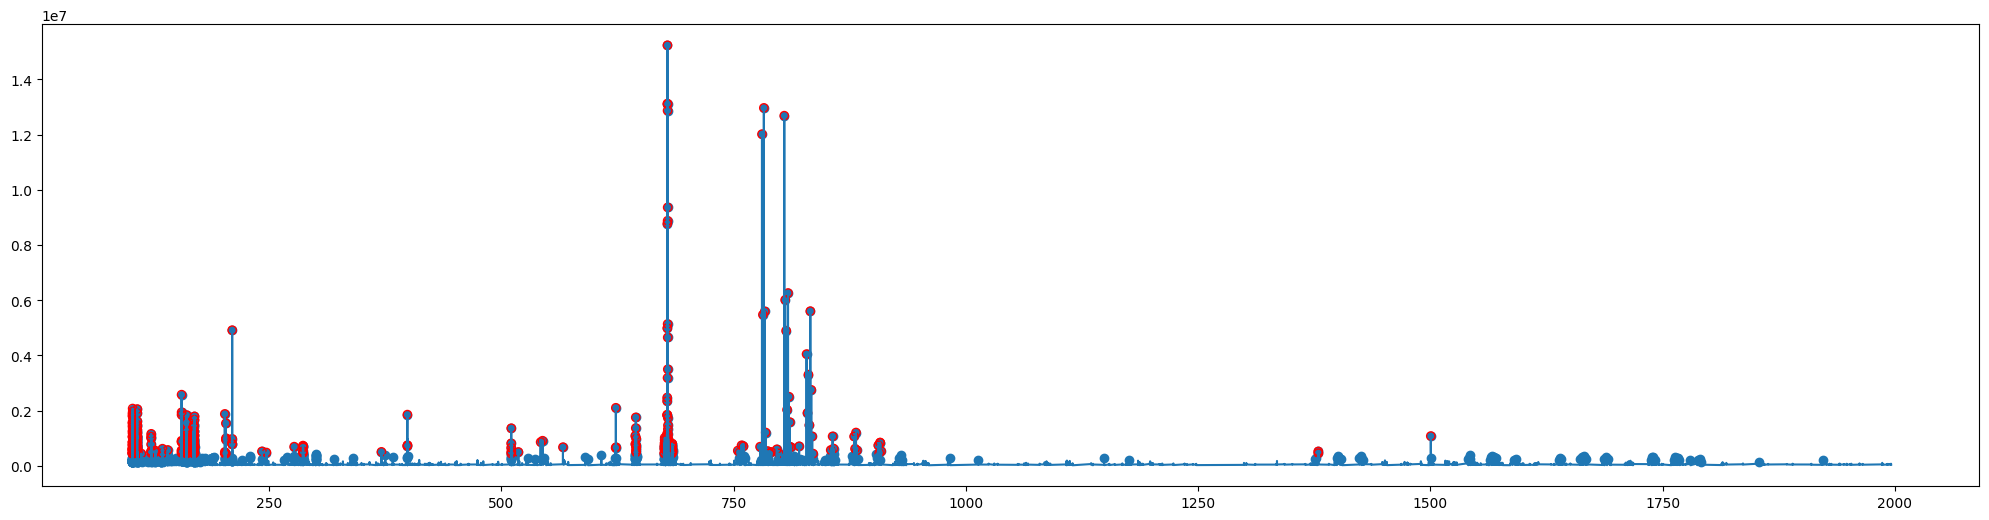

In [ ]:
plt.figure(figsize=(25, 6))
plt.plot(mz,intens)
plt.scatter(pmz_array,pint_array, marker='o')
plt.scatter(s[:,1],s[:,2], marker='o', facecolors='none', edgecolors='r')
# plt.xlim(*xlim)
# plt.ylim(bottom=0,top=intens[(xlim[0]< mz) & (xlim[1] > mz)].max()+1)